In [1]:
# Previous Colab setup — do not run in Kaggle.
# from google.colab import drive
# drive.mount("/content/drive")

!git clone --depth 1 https://github.com/Osanda-Induwara/Multimodel_chatgpt.git /kaggle/working/Multimodel_chatgpt
%cd /kaggle/working/Multimodel_chatgpt
!pip install -q -r requirements.txt

Cloning into '/kaggle/working/Multimodel_chatgpt'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 28 (delta 3), reused 23 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 1.57 MiB | 42.38 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/kaggle/working/Multimodel_chatgpt


In [2]:
!grep -n "KAGGLE" src/runtime.py

9:KAGGLE_DATASET_ROOTS = [
27:    return bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE")) or Path("/kaggle/input").exists()
46:        for dataset_root in KAGGLE_DATASET_ROOTS:


In [3]:
!find /kaggle/input -maxdepth 3 -type d

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/osandainduwara
/kaggle/input/datasets/osandainduwara/tea-liquor-dataset


In [4]:
%cd /kaggle/working/Multimodel_chatgpt
!git pull

/kaggle/working/Multimodel_chatgpt
Already up to date.


In [5]:
from pathlib import Path

runtime_file = Path("/kaggle/working/Multimodel_chatgpt/src/runtime.py")
source = runtime_file.read_text()

new_path = '    Path("/kaggle/input/datasets/osandainduwara/tea-liquor-dataset"),\n'
anchor = '    Path("/kaggle/input/tea_liquor_dataset"),\n'

if new_path not in source:
    runtime_file.write_text(source.replace(anchor, anchor + new_path))

print("Kaggle dataset path added.")

Kaggle dataset path added.


In [6]:
%cd /kaggle/working/Multimodel_chatgpt

!python scripts/train_grade.py --model mobilenet --epochs 10 --batch-size 32 --lr 0.0003 --weight-decay 0.0001 --image-size 160 --patience 4

/kaggle/working/Multimodel_chatgpt
Created manifest with 953 images: /kaggle/working/Multimodel_chatgpt/data/manifest.csv
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
100%|███████████████████████████████████████| 9.83M/9.83M [00:00<00:00, 210MB/s]
epoch 01/10: train_acc=0.557, valid_acc=0.138
epoch 02/10: train_acc=0.665, valid_acc=0.196
epoch 03/10: train_acc=0.759, valid_acc=0.277
epoch 04/10: train_acc=0.812, valid_acc=0.496
epoch 05/10: train_acc=0.838, valid_acc=0.518
epoch 06/10: train_acc=0.872, valid_acc=0.522
epoch 07/10: train_acc=0.888, valid_acc=0.460
epoch 08/10: train_acc=0.870, valid_acc=0.424
epoch 09/10: train_acc=0.892, valid_acc=0.518
epoch 10/10: train_acc=0.893, valid_acc=0.478
Early stopping after 10 epochs (no validation improvement for 4 epochs).
Finished. Results: /kaggle/working/Multimodel_chatgpt/results/grade/20261025-043542_mobilenet_baseline
Best val

Using: /kaggle/working/Multimodel_chatgpt/results/grade/20261025-043542_mobilenet_baseline


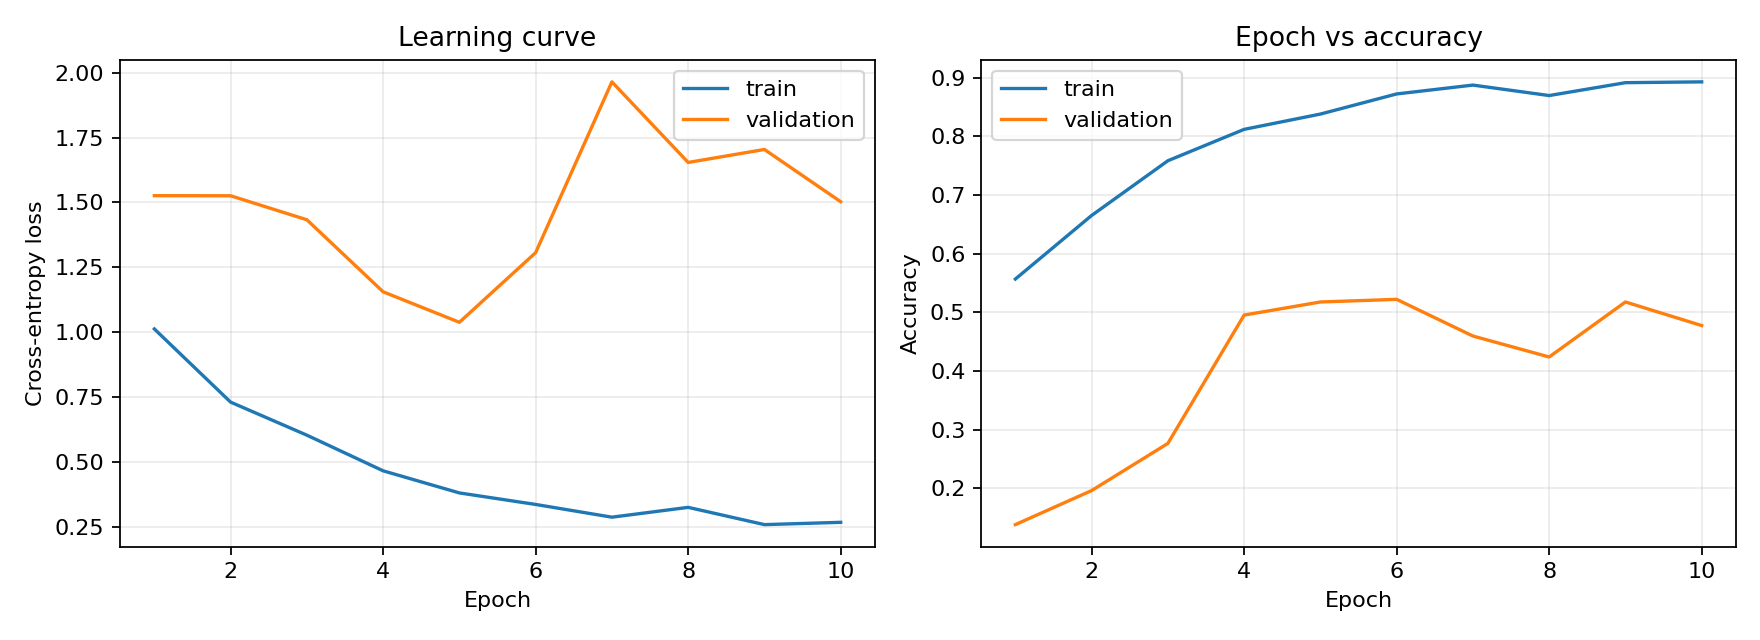

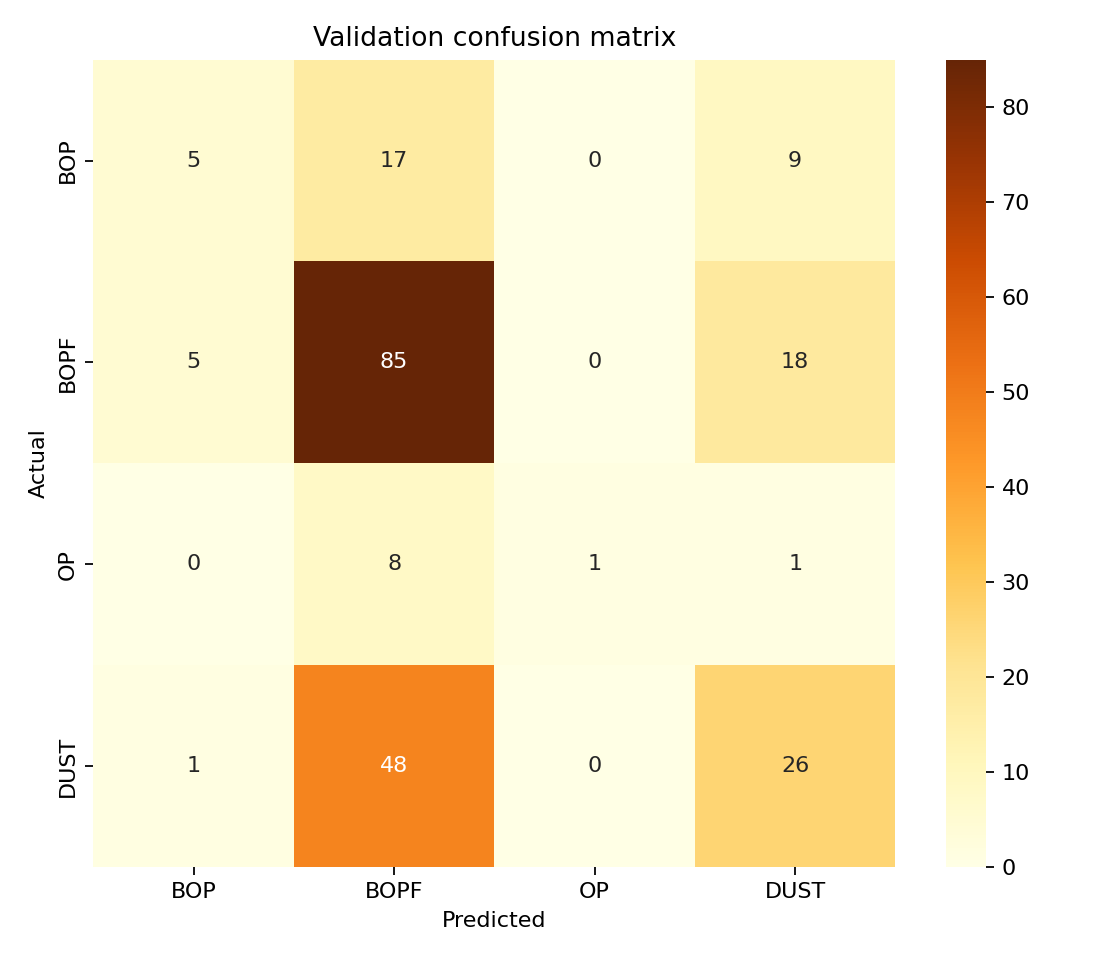

In [7]:
from pathlib import Path
from IPython.display import Image, display

base = Path("/kaggle/working/Multimodel_chatgpt/results/grade")

runs = sorted(
    [p for p in base.iterdir() if p.is_dir()],
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

RUN = runs[0]

print("Using:", RUN)

for name in ["learning_curves.png", "confusion_matrix.png"]:
    path = RUN / name

    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"Not found: {path}")

In [8]:
!python scripts/train_grade.py --model efficientnet --epochs 12 --batch-size 16 --lr 0.0003 --weight-decay 0.0001 --image-size 224 --patience 4

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|███████████████████████████████████████| 20.5M/20.5M [00:00<00:00, 120MB/s]
epoch 01/12: train_acc=0.562, valid_acc=0.571
epoch 02/12: train_acc=0.731, valid_acc=0.455
epoch 03/12: train_acc=0.820, valid_acc=0.527
epoch 04/12: train_acc=0.864, valid_acc=0.562
epoch 05/12: train_acc=0.896, valid_acc=0.558
Early stopping after 5 epochs (no validation improvement for 4 epochs).
Finished. Results: /kaggle/working/Multimodel_chatgpt/results/grade/20261025-044430_efficientnet_baseline
Best validation accuracy: 0.554


In [9]:
!python scripts/train_region.py --model efficientnet --epochs 12 --batch-size 16 --lr 0.0003 --weight-decay 0.0001 --image-size 224 --patience 4

epoch 01/12: train_acc=0.560, valid_acc=0.446
epoch 02/12: train_acc=0.717, valid_acc=0.616
epoch 03/12: train_acc=0.812, valid_acc=0.509
epoch 04/12: train_acc=0.885, valid_acc=0.513
epoch 05/12: train_acc=0.903, valid_acc=0.504
epoch 06/12: train_acc=0.930, valid_acc=0.589
Early stopping after 6 epochs (no validation improvement for 4 epochs).
Finished. Results: /kaggle/working/Multimodel_chatgpt/results/region/20261025-045216_efficientnet_baseline
Best validation accuracy: 0.616


In [10]:
!python scripts/tune.py --task grade --model efficientnet --trials 6 --epochs 8
!python scripts/compare_experiments.py --task grade

epoch 01/8: train_acc=0.556, valid_acc=0.411
epoch 02/8: train_acc=0.691, valid_acc=0.438
epoch 03/8: train_acc=0.752, valid_acc=0.527
epoch 04/8: train_acc=0.791, valid_acc=0.513
epoch 05/8: train_acc=0.829, valid_acc=0.473
epoch 06/8: train_acc=0.841, valid_acc=0.451
epoch 07/8: train_acc=0.885, valid_acc=0.464
epoch 08/8: train_acc=0.892, valid_acc=0.567
trial 1: validation accuracy 0.567
epoch 01/8: train_acc=0.534, valid_acc=0.487
epoch 02/8: train_acc=0.724, valid_acc=0.531
epoch 03/8: train_acc=0.813, valid_acc=0.460
epoch 04/8: train_acc=0.855, valid_acc=0.562
epoch 05/8: train_acc=0.886, valid_acc=0.464
epoch 06/8: train_acc=0.893, valid_acc=0.496
epoch 07/8: train_acc=0.931, valid_acc=0.496
epoch 08/8: train_acc=0.951, valid_acc=0.545
trial 2: validation accuracy 0.562
epoch 01/8: train_acc=0.502, valid_acc=0.420
epoch 02/8: train_acc=0.609, valid_acc=0.571
epoch 03/8: train_acc=0.708, valid_acc=0.603
epoch 04/8: train_acc=0.783, valid_acc=0.594
epoch 05/8: train_acc=0.840, v